# Surrogate distillation and SHAP fidelity (F09, spec 5.8)

The policy is a small MLP. `shap.TreeExplainer` cannot explain an MLP at all, and
`shap.KernelExplainer` would need thousands of forward passes per decision — the
mistake the master spec's F-25 caught in v2, where the stated budget worked out to
roughly a billion forward passes.

The v3 answer (A-04) is a two-path design. A gradient-boosted tree surrogate is
distilled to imitate the policy, exact TreeSHAP runs on *that* cheaply, and the
approximation is turned into a transparency feature by reporting how faithful the
surrogate is. `shap.GradientExplainer` then cross-checks a sample of decisions on the
true network, and the rank correlation between the two attribution sets is reported as
an integrity statistic.

This notebook reads what `make explain` wrote and shows the numbers behind the badge.
It fits nothing itself: the pipeline is the artifact, this is the reading of it.

In [1]:
import json

import numpy as np

from senna import config
from senna.explain import plots

cfg = config.load("explain")
THRESHOLD = config.get(cfg, "fidelity.threshold")

version = json.loads((config.REPO_ROOT / "models/headline/manifest.json").read_text())["model_version"]
artifacts = config.REPO_ROOT / "models/explain" / version
fidelity = json.loads((artifacts / "fidelity.json").read_text())

print(f"explaining {version}")
print(f"{fidelity['pairs']:,} distillation pairs from {fidelity['episodes']} episodes")
print(f"{fidelity['cards']:,} cards across {fidelity['card_races']} evaluation races")

explaining senna-ppo-6b6edb78d84e-C-00835584
200,009 distillation pairs from 3320 episodes
14,460 cards across 240 evaluation races


## The fidelity badge

Top-1 agreement is measured on held-out states — and the holdout is split at *episode*
level, not state level. Consecutive laps of one race are near-duplicates of each other;
a random state-level split would put a lap in training and its neighbour in holdout,
and the badge would read high for the wrong reason.

Agreement is also scored the way a card consumes the surrogate: masked to the legal
actions and renormalised. A surrogate whose raw argmax is an illegal action still
agrees with the policy once the mask is applied, and pretending otherwise would
understate a surrogate that is fine in use.

pit   top-1 0.9970  clears the 0.90 gate   mean KL 0.0141 nats   (depth 6, 300 trees)
mode  top-1 0.9908  clears the 0.90 gate   mean KL 0.0077 nats   (depth 6, 300 trees)


PosixPath('/Users/saad/senna/docs/explain/kl.png')

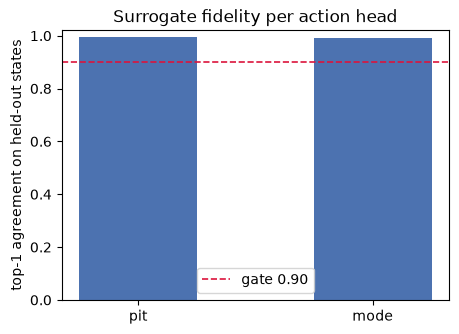

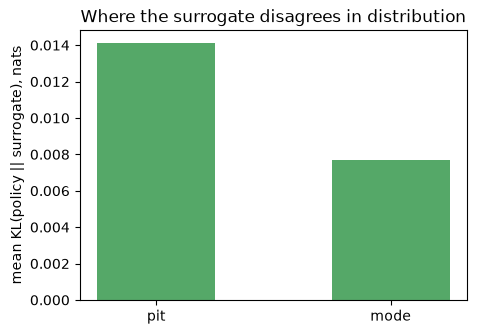

In [2]:
heads = fidelity["heads"]
for head, stats in heads.items():
    verdict = "clears" if stats["top1"] >= THRESHOLD else "MISSES"
    print(f"{head:5s} top-1 {stats['top1']:.4f}  {verdict} the {THRESHOLD:.2f} gate   "
          f"mean KL {stats['mean_kl']:.4f} nats   "
          f"(depth {stats['rung']['max_depth']}, {stats['rung']['n_estimators']} trees)")

plots.save_figure(plots.fidelity_bars(heads, THRESHOLD), "fidelity")
plots.save_figure(plots.kl_bars(heads), "kl")

The KL is the second opinion on the same question. Top-1 agreement only asks whether
the argmax matches; mean KL(policy ‖ surrogate) asks whether the whole shape of the
distribution matches, which is what the SHAP attributions are actually computed from. A
head can score well on agreement and still be a poor twin if it is confident where the
policy was torn — the KL would show that, and here it does not.

## The background set

A SHAP value is a marginal contribution *relative to a background distribution of
typical race states*. Change the background and the numbers change, so the choice is
documented rather than assumed: 1,024 states stratified across circuit, race phase and
track status.

The even-share-first rule matters. Safety-car and VSC laps are rare, and a purely
proportional draw would leave almost none in the background — precisely the states the
interesting pit calls live in.

1024 states across 204 non-empty strata
  green    364  (35.5%)
  vsc      330  (32.2%)
  sc       330  (32.2%)


PosixPath('/Users/saad/senna/docs/explain/background.png')

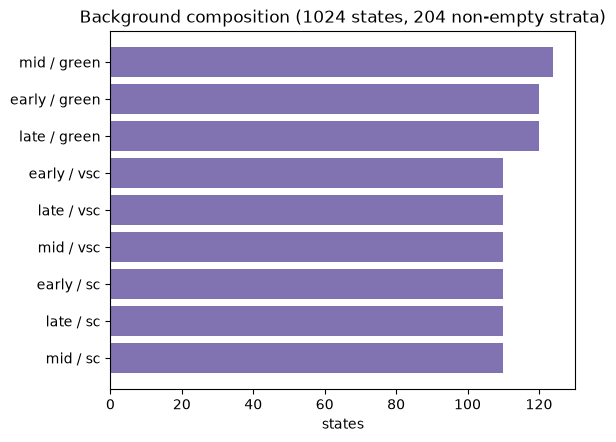

In [3]:
composition = json.loads((artifacts / "background_composition.json").read_text())
strata = composition["strata"]

by_status = {}
for key, count in strata.items():
    by_status[key.split("|")[2]] = by_status.get(key.split("|")[2], 0) + count

print(f"{composition['size']} states across {len(strata)} non-empty strata")
for status, count in sorted(by_status.items(), key=lambda kv: -kv[1]):
    print(f"  {status:6s} {count:5d}  ({count / composition['size']:.1%})")

plots.save_figure(plots.background_composition(composition), "background")

## Cross-check on the true network

Everything above explains the *surrogate*. The honest question is whether the surrogate's
story matches the network's, so `shap.GradientExplainer` attributes a sample of decisions
on the real MLP and the two attribution vectors are rank-correlated per decision.

Rank correlation, not raw agreement, is the right comparison: the two explainers work in
different input scales (raw observation against VecNormalize'd observation), so their
magnitudes are not directly comparable, but the *ordering* of which features mattered is.
A card names the top five drivers, so ordering is exactly what the card claims.

mean Spearman rho 0.687 over 500 sampled decisions
median 0.699   IQR 0.643 to 0.745
share positive: 100.0%


PosixPath('/Users/saad/senna/docs/explain/crosscheck.png')

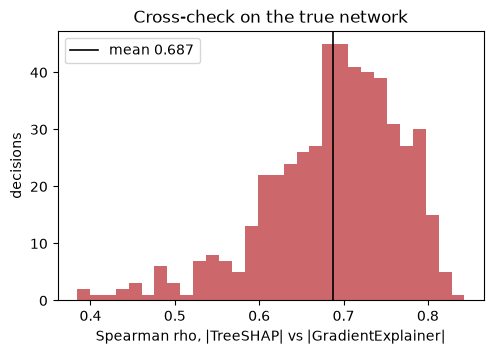

In [4]:
rhos = np.load(artifacts / "crosscheck.npz")["pit_spearman_rho"]

print(f"mean Spearman rho {rhos.mean():.3f} over {len(rhos)} sampled decisions")
print(f"median {np.median(rhos):.3f}   IQR {np.percentile(rhos, 25):.3f} to {np.percentile(rhos, 75):.3f}")
print(f"share positive: {(rhos > 0).mean():.1%}")

plots.save_figure(plots.rank_correlation_hist(rhos), "crosscheck")

This number deserves plain speech rather than a good look. A moderate positive
correlation says the two views agree on the broad ordering of drivers and disagree in the
tail — which is what should be expected of a tree surrogate against a smooth network, and
is a more honest result than a near-1.0 would be.

It is a reason to phrase a decision card as *this is what moved the model most* and never
as *this is why the model decided*, and it is why the card's honesty footer carries the
fidelity number on every single explanation. The claim the pipeline supports is an
attribution of the trained policy's sensitivity, not a causal statement about racing.